#  Asthma Detection with WaveNet — Homework Assignment

**Objective**: Build a full pipeline that trains a **WaveNet classifier** (using raw audio) on lung sounds to detect respiratory conditions such as asthma, COPD, etc.

**WaveNet** is an advanced architecture specially designed for audio. It leverages **dilated causal 1D convolutions**, **gated activations**, and **residual plus skip connections** to efficiently capture long-range temporal dependencies **without exploding compute or parameter growth**. The dilation exponentially expands the receptive field, enabling the network to incorporate broader context using a modest number of layers. This design outperforms standard 1D CNNs in modeling long-range audio structures while maintaining training efficiency and stable convergence through residual learning.


### 1️⃣ Download the dataset

In [1]:
import kagglehub
path = kagglehub.dataset_download("mohammedtawfikmusaed/asthma-detection-dataset-version-2")
print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/asthma-detection-dataset-version-2


In [2]:
# =========================================================
# Imports & global config
# =========================================================
import os, math, random, time
from pathlib import Path
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchaudio
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, accuracy_score, classification_report
import matplotlib.pyplot as plt


In [3]:
# Repro
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [4]:
TARGET_SR = 4000
CLIP_SECONDS = 2.0
MAX_LEN = int(TARGET_SR * CLIP_SECONDS)
BATCH_SIZE = 32
EPOCHS = 30
LR = 2e-3
WD = 1e-4
NUM_FOLDS = 5
NUM_WORKERS = 2
EPS = 1e-9
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("using device ",DEVICE)

using device  cuda


In [5]:
DATA_DIR = path+"/Asthma Detection Dataset Version 2/Asthma Detection Dataset Version 2"
CLASS_NAMES = ["asthma", "Bronchial", "copd", "healthy", "pneumonia"]
label2id = {c:i for i,c in enumerate(CLASS_NAMES)}
id2label = {i:c for c,i in label2id.items()}

In [6]:
print("the path is",DATA_DIR)
print("the path contains theese files",os.listdir(DATA_DIR))
print("the asthma folder contains",os.listdir(DATA_DIR+"/asthma")[:3])

the path is /kaggle/input/asthma-detection-dataset-version-2/Asthma Detection Dataset Version 2/Asthma Detection Dataset Version 2
the path contains theese files ['Bronchial', 'pneumonia', 'asthma', 'healthy', 'copd']
the asthma folder contains ['P4AsthmaRS_20.wav', 'P49WheezingIE_245.wav', 'P31WheezingIE_153.wav']


## [TODO] Build a DataFrame from folders

**Instructions:**  
- Traverse each class folder under `DATA_DIR` using `CLASS_NAMES`.  
- For every `.wav` file, record:
  - `path`: the string path to the file  
  - `label`: integer label via `label2id[class_name]`  
- Combine these records into a pandas DataFrame.  
- Shuffle the DataFrame using `random_state=SEED` for reproducibility.  
- Print out the label counts to verify distribution.


In [7]:
# =========================================================
# Build dataframe from directory structure
# =========================================================
def build_df(root: Path, class_names, label2id):
    records = []
    for cls in class_names:
        wav_files = (root / cls).glob("*.wav")
        for wav in wav_files:
            records.append({
                "path": str(wav),
                "label": label2id[cls]
            })
    df = pd.DataFrame(records)
    df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)  # shuffle
    return df
df = build_df(Path(DATA_DIR), CLASS_NAMES, label2id)
print(len(df))
print(df["label"].head())
print("Total Files",len(df))

1211
0    0
1    2
2    3
3    0
4    2
Name: label, dtype: int64
Total Files 1211


In [9]:
# Print counts of each label
print(df['label'].value_counts())

label
2    401
0    288
4    285
3    133
1    104
Name: count, dtype: int64


In [12]:
durations = []
for path in df['path']:
    info = torchaudio.info(path)
    durations.append(info.num_frames / info.sample_rate)
import numpy as np
print(f"Min duration: {np.min(durations):.2f}s")
print(f"Max duration: {np.max(durations):.2f}s")
print(f"Mean duration: {np.mean(durations):.2f}s")


/tmp/ipython-input-1835260974.py:3: UserWarning: torchaudio._backend.utils.info has been deprecated. This deprecation is part of a large refactoring effort to transition TorchAudio into a maintenance phase. The decoding and encoding capabilities of PyTorch for both audio and video are being consolidated into TorchCodec. Please see https://github.com/pytorch/audio/issues/3902 for more information. It will be removed from the 2.9 release. 
  info = torchaudio.info(path)
/usr/local/lib/python3.12/dist-packages/torchaudio/_backend/ffmpeg.py:20: UserWarning: torio.io._streaming_media_decoder.StreamingMediaDecoder has been deprecated. This deprecation is part of a large refactoring effort to transition TorchAudio into a maintenance phase. The decoding and encoding capabilities of PyTorch for both audio and video are being consolidated into TorchCodec. Please see https://github.com/pytorch/audio/issues/3902 for more information. It will be removed from the 2.9 release. 
  s = torchaudio.io.St

Min duration: 0.48s
Max duration: 6.00s
Mean duration: 5.91s


In [13]:
# Number of samples to listen to
from IPython.display import Audio
import random
import torchaudio
for idx in range(3):
    path = df['path'].iloc[idx]
    label = df['label'].iloc[idx]

    # Load audio
    waveform, sr = torchaudio.load(path)
    # Convert to mono if needed
    if waveform.shape[0] > 1:
        waveform = waveform.mean(dim=0)
    print(f"Class: {id2label[label]} ")
    display(Audio(waveform.numpy(), rate=sr))


Class: asthma 


/usr/local/lib/python3.12/dist-packages/torchaudio/_backend/utils.py:213: UserWarning: In 2.9, this function's implementation will be changed to use torchaudio.load_with_torchcodec` under the hood. Some parameters like ``normalize``, ``format``, ``buffer_size``, and ``backend`` will be ignored. We recommend that you port your code to rely directly on TorchCodec's decoder instead: https://docs.pytorch.org/torchcodec/stable/generated/torchcodec.decoders.AudioDecoder.html#torchcodec.decoders.AudioDecoder.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchaudio/_backend/ffmpeg.py:88: UserWarning: torio.io._streaming_media_decoder.StreamingMediaDecoder has been deprecated. This deprecation is part of a large refactoring effort to transition TorchAudio into a maintenance phase. The decoding and encoding capabilities of PyTorch for both audio and video are being consolidated into TorchCodec. Please see https://github.com/pytorch/audio/issues/3902 for more information. It will be r

Class: copd 


Class: healthy 


### [TODO] Audio loader: resample, mono, normalize, pad/trim to 5s

**Instructions:**  
- Use `torchaudio.load(path)` to get `waveform [C, T]` and sample rate `sr`.  
- Convert to mono by averaging channels if `C > 1`.  
- If `sr != TARGET_SR`, resample with `torchaudio.functional.resample`.  
- Normalize amplitude by dividing by `max(abs(x)) + ε`.  
- Pad with zeros or trim so that the final tensor has length `MAX_LEN`.  
- Return a tensor of shape `[1, T]`.


In [15]:
# =========================================================
# Audio loading utils
# =========================================================
def load_wave_fixed(path: str):
    wav, sr = torchaudio.load(path)
    if wav.shape[0] > 1:
        wav = wav.mean(dim=0, keepdim=True)  # [1, T]

    if sr != TARGET_SR:
        wav = torchaudio.functional.resample(wav, orig_freq=sr, new_freq=TARGET_SR)
    wav = wav / (wav.abs().max() + EPS)
    if wav.shape[1] < MAX_LEN:
        pad_amount = MAX_LEN - wav.shape[1]
        wav = torch.nn.functional.pad(wav, (0, pad_amount))
    else:
        wav = wav[:, :MAX_LEN]

    return wav

In [16]:
load_wave_fixed(df['path'][0])

tensor([[-0.1488, -0.1498, -0.1507,  ..., -0.2731, -0.2898, -0.3061]])

In [17]:
load_wave_fixed(df['path'][0]).shape

torch.Size([1, 8000])

### [TODO] Dataset & DataLoaders (+ class weights)

**Instructions:**  
1. Implement `LungSoundsDataset`:
   - Accept a DataFrame in the constructor and store it.
   - `__len__` returns number of rows.
   - `__getitem__(idx)` returns `(x, y)` where:
     - `x` is your preprocessed waveform `[1, T]`
     - `y` is the integer label.

2. Create `make_loaders(train_df, val_df)`:
   - Train loader: `shuffle=True`, `drop_last=True`.
   - Validation loader: `shuffle=False`.

3. Compute class weights:
   - `calculate counts`
   - `class_weights = total_sum / counts`
   - `class_weights = class_weights / class_weights.mean()` to scale ≈ 1.


In [18]:
class LungSoundsDataset(Dataset):
    def __init__(self, df, target_sr, max_len):
        self.df = df.reset_index(drop=True)
        self.target_sr = target_sr
        self.max_len = max_len

    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        path = row['path']
        label = row['label']
        x = load_wave_fixed(path)
        y = torch.tensor(label, dtype=torch.long)
        return x, y

def make_loaders(train_df, val_df):
    train_dataset = LungSoundsDataset(train_df, TARGET_SR, MAX_LEN)
    val_dataset = LungSoundsDataset(val_df, TARGET_SR, MAX_LEN)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

    counts = train_df['label'].value_counts().sort_index().values
    total = counts.sum()
    class_weights = total / counts
    class_weights = class_weights / class_weights.mean()

    class_weights = torch.tensor(class_weights, dtype=torch.float32)

    return train_loader, val_loader, class_weights


### [TODO] Implement WaveNet

**Instructions:**  
You will implement a WaveNet-style classifier including:  
- **CausalConv1d**: causal convolution with left padding growing with dilation.  
- **WaveNetResidualBlock**: gated residual unit with filter conv, gate conv, dropout, and both residual + skip 1x1 convolutions.  
- **WaveNetClassifier**:
  - Input projection via 1x1 conv.  
  - Stack multiple residual blocks with exponentially increasing dilations per stack.  
  - Sum skip connections from all blocks.  
  - Head: ReLU → 1x1 conv → ReLU → 1x1 conv to produce class logits.  
  - Apply global average pooling over the time dimension.  


In [19]:
class CausalConv1d(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size=2, dilation=1):
        super().__init__()
        self.pad = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(in_ch, out_ch, kernel_size, padding=0, dilation=dilation)

    def forward(self, x):
        x = F.pad(x, (self.pad, 0))
        return self.conv(x)
class WaveNetResidualBlock(nn.Module):
    def __init__(self, channels, skip_channels,
                 kernel_size=2, dilation=1, dropout=0.05):
        super().__init__()
        self.filter_conv = CausalConv1d(channels, channels,
                                        kernel_size, dilation)
        self.gate_conv   = CausalConv1d(channels, channels,
                                        kernel_size, dilation)
        self.dropout = nn.Dropout(dropout)

        self.res_conv  = nn.Conv1d(channels, channels, kernel_size=1)
        self.skip_conv = nn.Conv1d(channels, skip_channels, kernel_size=1)

    def forward(self, x):
        f = torch.tanh(self.filter_conv(x))
        g = torch.sigmoid(self.gate_conv(x))
        z = self.dropout(f * g)

        res  = self.res_conv(z)
        skip = self.skip_conv(z)

        out = x + res
        return out, skip
class WaveNetClassifier(nn.Module):
    """
    Stacked dilated causal conv blocks with skip aggregation and global pooling.
    Suitable for clip-level classification on raw waveforms [B, 1, T].
    """
    def __init__(self, num_classes, in_channels=1, res_channels=64,
                 skip_channels=128, kernel_size=2,
                 layers_per_stack=10, num_stacks=2, dropout=0.05):
        super().__init__()
        self.input_proj = nn.Conv1d(in_channels, res_channels, kernel_size=1)
        self.blocks = nn.ModuleList()
        for s in range(num_stacks):
            for l in range(layers_per_stack):
                dilation = 2 ** l
                self.blocks.append(
                    WaveNetResidualBlock(res_channels, skip_channels,
                                         kernel_size, dilation, dropout)
                )
        self.out = nn.Sequential(
            nn.ReLU(),
            nn.Conv1d(skip_channels, skip_channels, kernel_size=1),
            nn.ReLU(),
            nn.Conv1d(skip_channels, num_classes, kernel_size=1)
        )
    def forward(self, x):
        x = self.input_proj(x)
        skip_sum = 0

        for block in self.blocks:
            x, skip = block(x)
            skip_sum = skip_sum + skip

        y = self.out(F.relu(skip_sum))
        y = y.mean(dim=-1)
        return y
model = WaveNetClassifier(num_classes=len(CLASS_NAMES)).to(DEVICE)
print(f"{sum(p.numel() for p in model.parameters())/1e6:.2f} M params")

0.60 M params


## Training and Validation loops

In [20]:
# =========================================================
# Optimizer, scheduler, loss; eval helpers
# =========================================================
scaler = torch.cuda.amp.GradScaler(enabled=True)

def make_optimizer(model):
    return torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)

def train_one_epoch(model, loader, criterion, optimizer, scaler=None):
    model.train()
    losses = []
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        if scaler is not None:
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(x)
                loss = criterion(logits, y)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
        losses.append(loss.item())
    return float(np.mean(losses))

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    all_preds, all_tgts = [], []
    losses = []
    criterion_eval = nn.CrossEntropyLoss()
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)
        logits = model(x)
        loss = criterion_eval(logits, y)
        preds = logits.argmax(1)
        losses.append(loss.item())
        all_preds.append(preds.detach().cpu().numpy())
        all_tgts.append(y.detach().cpu().numpy())
    y_pred = np.concatenate(all_preds)
    y_true = np.concatenate(all_tgts)
    acc = accuracy_score(y_true, y_pred)
    f1m = f1_score(y_true, y_pred, average="macro")
    return float(np.mean(losses)), acc, f1m, y_true, y_pred


/tmp/ipython-input-3308053687.py:4: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=True)


### [TODO] K-fold training loop + early stopping + checkpointing

**Instructions:**  
- Initialize `StratifiedKFold(NUM_FOLDS, shuffle=True, random_state=SEED)`.  
- Loop over folds:
  - Split DataFrame into train/val.
  - Build DataLoaders, model (WaveNet), optimizer, scaler, and criterion using weighted loss.
  - Initialize lists `train_losses`, `val_losses` for tracking.
  - For each epoch:
    - Run `train_one_epoch(...)`, then `evaluate(...)`, append losses, compute metrics.
    - Print epoch metrics (losses, acc, macro-F1).
    - If the validation macro-F1 improves, save model checkpoint and reset patience.
    - If patience exceeds limit, break training loop early.
  - After fold completion, load the best model, evaluate, print classification report, and log fold metrics (accuracy, F1).


In [21]:
scaler = torch.cuda.amp.GradScaler(enabled=True)


/tmp/ipython-input-2493587239.py:1: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=True)


In [23]:
# =========================================================
# Train across folds (clean output, with classification report)
# =========================================================
from sklearn.metrics import classification_report
from sklearn.model_selection import StratifiedKFold
import torch
import torch.nn as nn
import time
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

RUN_SINGLE_FOLD = True
SINGLE_FOLD_IDX = 0

skf = StratifiedKFold(n_splits=NUM_FOLDS, shuffle=True, random_state=SEED)
folds = list(skf.split(df["path"], df["label"]))
selected_folds = [folds[SINGLE_FOLD_IDX]] if RUN_SINGLE_FOLD else folds

history = []

for fold_idx, (tr_idx, va_idx) in enumerate(selected_folds):
    print(f"\n========== Fold {fold_idx} ==========")
    tr_df = df.iloc[tr_idx].reset_index(drop=True)
    va_df = df.iloc[va_idx].reset_index(drop=True)
    tr_loader, va_loader, class_weights = make_loaders(tr_df, va_df)
    class_weights = class_weights.to(DEVICE)
    model = WaveNetClassifier(num_classes=len(CLASS_NAMES)).to(DEVICE)
    optimizer = make_optimizer(model)
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    best_f1 = -1.0
    patience, patience_limit = 0, 6
    ckpt_path = f"best_fold{fold_idx}.pt"

    train_losses, val_losses = [], []
    for epoch in range(1, EPOCHS + 1):
        t0 = time.time()

        tr_loss = train_one_epoch(model, tr_loader, criterion, optimizer,scaler)

        va_loss, va_acc, va_f1, y_true, y_pred = evaluate(model, va_loader)

        train_losses.append(tr_loss)
        val_losses.append(va_loss)

        elapsed = time.time() - t0
        print(f"Epoch {epoch:02d} | tr_loss {tr_loss:.4f} | va_loss {va_loss:.4f} "
              f"| val_acc {va_acc:.4f} | val_f1 {va_f1:.4f} | {elapsed:.1f}s")
        if va_f1 > best_f1:
            best_f1 = va_f1
            patience = 0
            torch.save(model.state_dict(), ckpt_path)
            print(f" Saved new best model (F1={va_f1:.4f})")
        else:
            patience += 1
            if patience >= patience_limit:
                print("  Early stopping triggered")
                break
    model.load_state_dict(torch.load(ckpt_path))
    va_loss, va_acc, va_f1, y_true, y_pred = evaluate(model, va_loader)

    print(f"\nBest checkpoint results (Fold {fold_idx}):")
    print(f"VAL acc={va_acc:.4f}  macroF1={va_f1:.4f}")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

    history.append({
        "fold": fold_idx,
        "val_loss": va_loss,
        "val_acc": va_acc,
        "val_f1": va_f1,
        "train_losses": train_losses,
        "val_losses": val_losses,
    })


========== Fold 0 ==========
Epoch 01 | tr_loss 1.6175 | va_loss 1.5310 | val_acc 0.3909 | val_f1 0.2516 | 26.5s
 Saved new best model (F1=0.2516)
Epoch 02 | tr_loss 1.5355 | va_loss 1.4780 | val_acc 0.1728 | val_f1 0.1573 | 26.5s
Epoch 03 | tr_loss 1.3502 | va_loss 1.4536 | val_acc 0.4609 | val_f1 0.3150 | 26.8s
 Saved new best model (F1=0.3150)
Epoch 04 | tr_loss 1.3065 | va_loss 1.3869 | val_acc 0.4321 | val_f1 0.2900 | 27.9s
Epoch 05 | tr_loss 1.2464 | va_loss 1.1258 | val_acc 0.6091 | val_f1 0.5489 | 26.8s
 Saved new best model (F1=0.5489)
Epoch 06 | tr_loss 1.1586 | va_loss 1.2455 | val_acc 0.4733 | val_f1 0.4519 | 26.9s
Epoch 07 | tr_loss 1.1063 | va_loss 1.0786 | val_acc 0.5885 | val_f1 0.5434 | 31.4s
Epoch 08 | tr_loss 1.0160 | va_loss 1.0237 | val_acc 0.6132 | val_f1 0.5085 | 29.6s
Epoch 09 | tr_loss 0.9598 | va_loss 1.0814 | val_acc 0.5432 | val_f1 0.5011 | 29.8s
Epoch 10 | tr_loss 0.9604 | va_loss 1.0395 | val_acc 0.5391 | val_f1 0.4755 | 29.9s
Epoch 11 | tr_loss 0.9556 | 

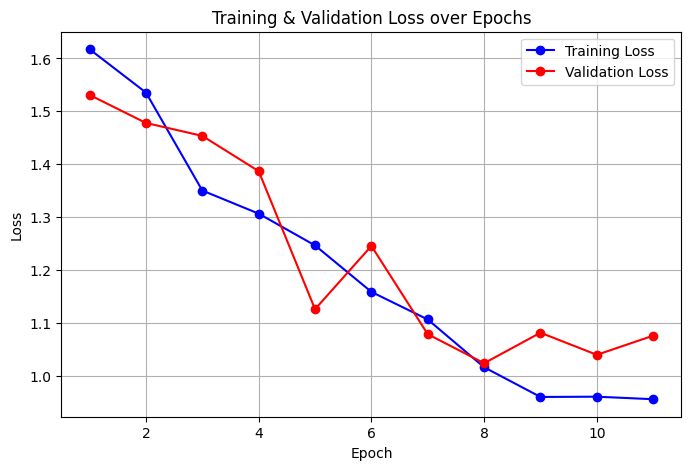

In [24]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, 'b-o', label='Training Loss')
plt.plot(epochs, val_losses,   'r-o', label='Validation Loss')
plt.title('Training & Validation Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

##  Evaluation Criteria

Your **Audio Classification** homework will be graded based on the following components:

| **Category**                     | **Weight** | **Details**                                                                 |
|----------------------------------|------------|------------------------------------------------------------------------------|
| **Implementation Correctness**   | **70%**    | - `build_df`, `load_wave_fixed`, `LungSoundsDataset`, and WaveNet modules are correctly implemented.<br> - Class weights are computed and used properly.<br> - Training loop, early stopping, and checkpoint saving are implemented correctly.<br> |
| **Training & Results**           | **20%**    | - Training and validation losses printed per epoch.<br> - Validation accuracy and macro-F1 score are computed and displayed.<br> - Best model is saved and loaded successfully for evaluation.<br> - Loss curves are plotted clearly. |
| **Code Quality & Structure**     | **10%**    | - Code follows modular structure with clear, commented `TODO`s.<br> - Cell-based notebook structure is clean and logical.<br> - Outputs (e.g., classification report, inference results) are printed clearly and readably. |
